# Gradient Clipping: Preventing Exploding Gradients

A teaching notebook. Gradient clipping rescales (or truncates) the gradient *before* the optimizer step, so a single huge gradient cannot throw the weights far away.

Every comparison below changes **only** the clipping rule: same data, same initialization, same learning rate, same seeds.

| # | Experiment | Question it answers |
|---|---|---|
| 0 | What clipping is | Norm clipping vs value clipping, and what each does to the gradient's direction |
| A | A loss "cliff" in 2D | *Why* can one gradient step ruin training? |
| B | Gradients through time | *Where* do exploding gradients come from in an RNN? |
| C | Training an RNN with and without clipping | Does clipping prevent divergence? (5 seeds, 3 learning rates) |
| D | Choosing the threshold | What happens if the threshold is too small or too large? |
| E | Norm vs value clipping | Do they behave differently in practice? |
| F | What clipping does **not** fix | Vanishing gradients |
| G | Practical recipe | How to use it correctly in PyTorch |

Runs on CPU. Total runtime is several minutes.

In [1]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(2)
print("torch", torch.__version__)

torch 2.15.0+cu132


## 0. What gradient clipping is

Let `g` be the gradient of the loss with respect to **all** parameters, flattened into one vector.

**Clip by norm** (global norm; Pascanu et al., 2013). If `||g||` exceeds a threshold `c`, shrink the whole vector so its norm equals `c`:

$$g \leftarrow g \cdot \min\!\left(1, \frac{c}{\lVert g \rVert_2}\right)$$

The **direction is unchanged**; only the length is capped.

**Clip by value.** Clamp each component independently into `[-c, c]`:

$$g_i \leftarrow \mathrm{clip}(g_i, -c, c)$$

This caps every coordinate but can **change the direction** of the update, because large components are cut while small ones are left alone.

In both cases a gradient that is already small is left untouched.

In [2]:
def clip_by_norm_(params, max_norm):
    """In-place global-norm clipping. Returns the pre-clip norm."""
    grads = [p.grad for p in params if p.grad is not None]
    total = torch.sqrt(sum((g ** 2).sum() for g in grads))
    scale = min(1.0, max_norm / (total.item() + 1e-6))
    for g in grads:
        g.mul_(scale)
    return total

def clip_by_value_(params, c):
    for p in params:
        if p.grad is not None:
            p.grad.clamp_(-c, c)

# --- verify our implementation against PyTorch's -----------------------------
torch.manual_seed(0)
def tiny_grads():
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(4, 8), nn.Tanh(), nn.Linear(8, 1))
    (net(torch.randn(16, 4)).pow(2).mean() * 50).backward()
    return net

a, b = tiny_grads(), tiny_grads()
n_ours = clip_by_norm_(list(a.parameters()), 1.0)
n_torch = torch.nn.utils.clip_grad_norm_(b.parameters(), 1.0)
same = all(torch.allclose(p.grad, q.grad, atol=1e-6) for p, q in zip(a.parameters(), b.parameters()))
print(f"pre-clip norm: ours {n_ours.item():.4f}, torch {n_torch.item():.4f}; clipped grads identical: {same}")

# --- direction: norm clipping preserves it, value clipping does not ----------
g = torch.tensor([10.0, 0.5, 0.5, -0.2])
g_norm = g * min(1.0, 1.0 / g.norm().item())
g_val = g.clamp(-1.0, 1.0)
cos = lambda u, v: F.cosine_similarity(u, v, dim=0).item()
print("raw gradient        :", g.tolist(), "  norm", round(g.norm().item(), 2))
print("clip by norm  (c=1) :", [round(v, 3) for v in g_norm.tolist()], "  cosine to raw =", round(cos(g, g_norm), 4))
print("clip by value (c=1) :", [round(v, 3) for v in g_val.tolist()], "  cosine to raw =", round(cos(g, g_val), 4))

pre-clip norm: ours 20.1535, torch 20.1535; clipped grads identical: True
raw gradient        : [10.0, 0.5, 0.5, -0.20000000298023224]   norm 10.03
clip by norm  (c=1) : [0.997, 0.05, 0.05, -0.02]   cosine to raw = 1.0
clip by value (c=1) : [1.0, 0.5, 0.5, -0.2]   cosine to raw = 0.8471


## Experiment A: a loss "cliff" (why one step can ruin training)

Pascanu et al. explain exploding gradients with a tiny recurrent model: a **single neuron** unrolled for `T = 50` steps,

$$x_t = w\,\sigma(x_{t-1}) + b,\qquad L(w, b) = \big(\sigma(x_T) - 0.7\big)^2 .$$

Because the same `w` is applied 50 times, the loss is flat over most of the `(w, b)` plane but has a **steep wall** where the system flips between two regimes. Near the wall the gradient is enormous, while elsewhere it is tiny.

Plain gradient descent that lands on the wall can take a giant step and be thrown onto a flat plateau where the gradient is almost zero, so it may never recover. Clipping caps the step length, so the iterate can walk along the wall instead.

In [3]:
T_TOY = 50
DT = torch.float64      # float64 on purpose: near the cliff, outcomes are sensitive to tiny numerical differences

def toy_loss(w, b, x0=0.5, target=0.7):
    x = x0 * torch.ones_like(w)
    for _ in range(T_TOY):
        x = w * torch.sigmoid(x) + b
    return (torch.sigmoid(x) - target) ** 2

# loss and gradient-norm maps
W = torch.linspace(0, 8, 161, dtype=DT); B = torch.linspace(-6, 2, 161, dtype=DT)
Wg, Bg = torch.meshgrid(W, B, indexing="ij")
Wg.requires_grad_(); Bg.requires_grad_()
Lgrid = toy_loss(Wg, Bg)
Lgrid.sum().backward()
gnorm = (Wg.grad ** 2 + Bg.grad ** 2).sqrt().detach().numpy()
Lgrid = Lgrid.detach().numpy()
print(f"gradient norm over the grid: median {np.median(gnorm):.3f}, 99th pct {np.percentile(gnorm, 99):.3f}, max {gnorm.max():.1f}")

def toy_gd(w0, b0, lr, steps=150, clip=None):
    p = torch.tensor([float(w0), float(b0)], dtype=DT, requires_grad=True)
    path = [p.detach().numpy().copy()]
    for _ in range(steps):
        l = toy_loss(p[0], p[1])
        g, = torch.autograd.grad(l, p)
        if clip is not None and g.norm() > clip:
            g = g * clip / g.norm()
        p = (p - lr * g).detach().requires_grad_(True)
        path.append(p.detach().numpy().copy())
    path = np.array(path)
    losses = np.array([toy_loss(torch.tensor(q[0], dtype=DT), torch.tensor(q[1], dtype=DT)).item() for q in path])
    return path, losses

gradient norm over the grid: median 0.018, 99th pct 0.375, max 26.0


### A1. How often does clipping matter? Tally over a grid of starts

Run gradient descent from a **grid of 49 start points** for several learning rates, with and without clipping (norm, `c = 1`), and count how many runs reach a low loss (< 0.01). We also count the starts where the two methods *disagree*, in **both** directions.

In [4]:
starts = [(w0, b0) for w0 in np.linspace(1, 7, 7) for b0 in np.linspace(-5, 1, 7)]
lrs = [0.03, 0.1, 0.3, 1.0]
t0 = time.time()
table = {}
for lr in lrs:
    for clip in (None, 1.0):
        table[(lr, clip)] = np.array([toy_gd(w0, b0, lr, steps=150, clip=clip)[1][-1] for w0, b0 in starts])
print(f"({time.time()-t0:.0f}s)")
print(f"{'lr':>5s} | {'no clip: loss<0.01':>18s} | {'clip c=1: loss<0.01':>19s} | {'only clip succeeds':>18s} | {'only no-clip succeeds':>21s}")
for lr in lrs:
    a, b = table[(lr, None)] < 0.01, table[(lr, 1.0)] < 0.01
    print(f"{lr:5.2f} | {a.sum():>15d}/49 | {b.sum():>16d}/49 | {(b & ~a).sum():>18d} | {(a & ~b).sum():>21d}")

(63s)
   lr | no clip: loss<0.01 | clip c=1: loss<0.01 | only clip succeeds | only no-clip succeeds
 0.03 |               9/49 |                9/49 |                  0 |                     0
 0.10 |              15/49 |               17/49 |                  2 |                     0
 0.30 |              24/49 |               27/49 |                  3 |                     0
 1.00 |              33/49 |               41/49 |                  8 |                     0


### A2. An example where clipping makes the difference

The tally says clipping helps in this toy, but modestly. To *see* the mechanism, take one of the starts (at `lr = 0.3`) where plain GD ends on the plateau and clipped GD reaches the minimum. This example is **selected** from the cases where the two methods disagree, so it shows the mechanism, not the typical outcome; the tally above is the fair summary.

3 of 49 starts at lr=0.3 have: no-clip stuck (loss > 0.05) and clip converged (loss < 0.01)


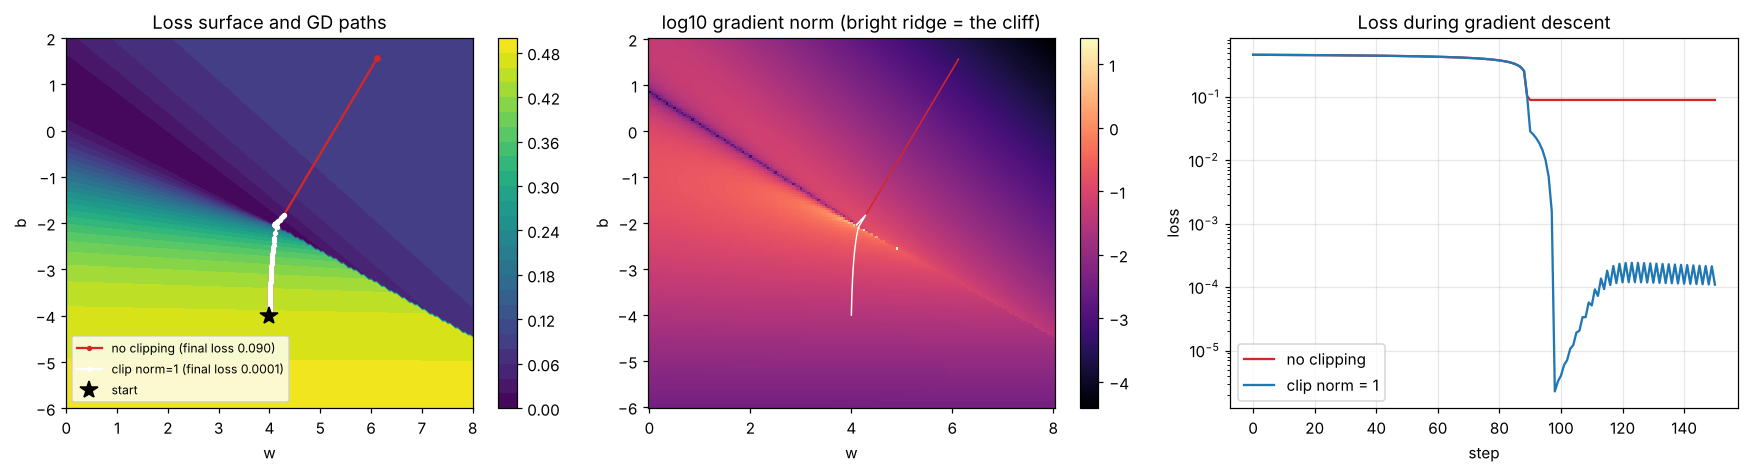

start (4.0, -4.0), lr 0.3
no clipping : largest single step = 4.16, final loss 0.0897
clip norm=1 : largest single step = 0.30, final loss 0.0001  (steps are capped at lr * c = 0.3)


In [5]:
LR = 0.3
no_fin, cl_fin = table[(LR, None)], table[(LR, 1.0)]
cand = [k for k in range(len(starts)) if no_fin[k] > 0.05 and cl_fin[k] < 0.01]
print(f"{len(cand)} of 49 starts at lr={LR} have: no-clip stuck (loss > 0.05) and clip converged (loss < 0.01)")
START = tuple(float(v) for v in starts[cand[0]])
path_no, loss_no = toy_gd(*START, LR, clip=None)
path_cl, loss_cl = toy_gd(*START, LR, clip=1.0)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
cs = ax.contourf(W.numpy(), B.numpy(), Lgrid.T, levels=30, cmap="viridis")
ax.plot(*path_no.T, "-o", ms=2.5, color="tab:red", label=f"no clipping (final loss {loss_no[-1]:.3f})")
ax.plot(*path_cl.T, "-o", ms=2.5, color="white", label=f"clip norm=1 (final loss {loss_cl[-1]:.4f})")
ax.plot(*START, "k*", ms=12, label="start")
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.set_title("Loss surface and GD paths"); ax.grid(False)
ax.legend(loc="lower left", fontsize=8); fig.colorbar(cs, ax=ax)

ax = axes[1]
im = ax.pcolormesh(W.numpy(), B.numpy(), np.log10(gnorm.T + 1e-12), cmap="magma", shading="auto")
ax.plot(*path_no.T, "-", lw=1, color="tab:red"); ax.plot(*path_cl.T, "-", lw=1, color="white")
ax.set_xlabel("w"); ax.set_ylabel("b"); ax.set_title("log10 gradient norm (bright ridge = the cliff)"); ax.grid(False)
fig.colorbar(im, ax=ax)

ax = axes[2]
ax.semilogy(loss_no, color="tab:red", label="no clipping")
ax.semilogy(loss_cl, color="tab:blue", label="clip norm = 1")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.set_title("Loss during gradient descent"); ax.legend()
plt.tight_layout(); plt.show()

print(f"start {START}, lr {LR}")
print(f"no clipping : largest single step = {np.linalg.norm(np.diff(path_no, axis=0), axis=1).max():.2f}, final loss {loss_no[-1]:.4f}")
print(f"clip norm=1 : largest single step = {np.linalg.norm(np.diff(path_cl, axis=0), axis=1).max():.2f}, final loss {loss_cl[-1]:.4f}  (steps are capped at lr * c = {LR})")

## Experiment B: where exploding gradients come from in an RNN

In backpropagation through time, the gradient reaching step `t` is a product of Jacobians,

$$\frac{\partial L}{\partial h_t} = \frac{\partial L}{\partial h_T}\prod_{k=t+1}^{T} \mathrm{diag}\big(\tanh'(a_k)\big)\, W_{hh}.$$

If the recurrent matrix `W_hh` has **spectral radius** (largest eigenvalue magnitude) above 1, this product tends to grow exponentially as it travels back in time; below 1 it shrinks.

We build the same tanh RNN with different spectral radii `rho` and measure `||dL/dh_t||` at initialization, for a 50-step sequence. Values are the median over 5 random networks.

One subtlety worth stating in class: `tanh'` is at most 1 and usually smaller, which shrinks the product. So with tanh the explosion only shows up clearly once `rho` is noticeably above 1.

In [6]:
class TanhRNN(nn.Module):
    """Vanilla tanh RNN, many-to-one regression. rho sets the spectral radius of W_hh at init."""
    def __init__(self, hidden=32, rho=2.0, seed=0):
        super().__init__()
        g = torch.Generator().manual_seed(seed)
        self.hidden = hidden
        self.Wxh = nn.Parameter(torch.randn(hidden, 1, generator=g) * 0.5)
        W = torch.randn(hidden, hidden, generator=g)
        W = W / torch.linalg.eigvals(W).abs().max() * rho
        self.Whh = nn.Parameter(W)
        self.bh = nn.Parameter(torch.zeros(hidden))
        self.out = nn.Linear(hidden, 1)

    def forward(self, x, return_states=False):          # x: (B, T, 1)
        h = torch.zeros(x.size(0), self.hidden)
        states = []
        for t in range(x.size(1)):
            h = torch.tanh(x[:, t] @ self.Wxh.T + h @ self.Whh.T + self.bh)
            states.append(h)
        y = self.out(h)
        return (y, states) if return_states else y


def make_data(n=512, T=50, task="last10", seed=0):
    """Regress the sum of 10 inputs, scaled to unit variance (so predicting the mean gives loss ~ 1)."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, T, 1, generator=g)
    y = (x[:, -10:] if task == "last10" else x[:, :10]).sum(1) / math.sqrt(10)
    return x, y


def bptt_profile(rho, seed, T=50):
    X, Y = make_data(T=T)
    net = TanhRNN(rho=rho, seed=seed)
    pred, states = net(X[:64], return_states=True)
    for s in states:
        s.retain_grad()
    F.mse_loss(pred, Y[:64]).backward()
    return np.array([s.grad.norm().item() for s in states])

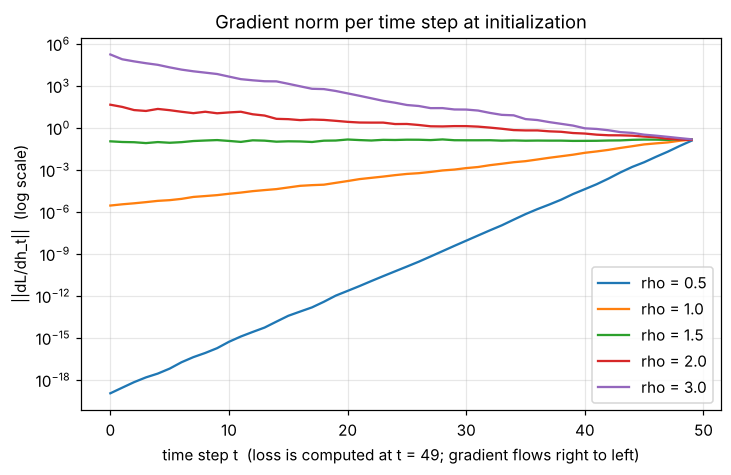

rho = 0.5:  ||dL/dh|| at t=49: 1.28e-01   at t=0: 1.15e-19   ratio (t=0 / t=49): 8.99e-19
rho = 1.0:  ||dL/dh|| at t=49: 1.51e-01   at t=0: 2.96e-06   ratio (t=0 / t=49): 1.95e-05
rho = 1.5:  ||dL/dh|| at t=49: 1.62e-01   at t=0: 1.14e-01   ratio (t=0 / t=49): 7.08e-01
rho = 2.0:  ||dL/dh|| at t=49: 1.44e-01   at t=0: 4.72e+01   ratio (t=0 / t=49): 3.28e+02
rho = 3.0:  ||dL/dh|| at t=49: 1.60e-01   at t=0: 1.83e+05   ratio (t=0 / t=49): 1.14e+06


In [7]:
rhos = [0.5, 1.0, 1.5, 2.0, 3.0]
profiles = {rho: np.median([bptt_profile(rho, s) for s in range(5)], axis=0) for rho in rhos}

plt.figure(figsize=(7.5, 4.4))
for rho, prof in profiles.items():
    plt.semilogy(np.arange(len(prof)), prof, label=f"rho = {rho}")
plt.xlabel("time step t  (loss is computed at t = 49; gradient flows right to left)")
plt.ylabel("||dL/dh_t||  (log scale)")
plt.title("Gradient norm per time step at initialization")
plt.legend(); plt.show()

for rho, prof in profiles.items():
    print(f"rho = {rho}:  ||dL/dh|| at t=49: {prof[49]:.2e}   at t=0: {prof[0]:.2e}   ratio (t=0 / t=49): {prof[0]/prof[49]:.2e}")

## Experiment C: training an RNN with and without clipping

Task: given a length-50 sequence of random numbers, predict the (scaled) **sum of the last 10 inputs**. Loss is MSE on a target with variance 1, so **a loss of 1.0 means "no better than predicting the mean"**.

Model: the tanh RNN above with `rho = 2.0` (so gradients through time are large). Optimizer: plain SGD. We compare *no clipping* with *clip-by-norm at 1.0* at three learning rates, over **5 seeds each**, and record the **pre-clip** gradient norm at every step so we can see what the optimizer was being hit with.

In [8]:
def train_rnn(clip=None, mode="norm", rho=2.0, lr=0.1, steps=300, seed=0, batch=64,
              task="last10", T=50, track_cos=False):
    torch.manual_seed(seed)
    X, Y = make_data(T=T, task=task)
    net = TanhRNN(rho=rho, seed=seed)
    params = list(net.parameters())
    opt = torch.optim.SGD(params, lr=lr)
    losses = np.full(steps, np.nan); norms = np.full(steps, np.nan); coss = []
    diverged = False
    for s in range(steps):
        idx = torch.randint(0, len(X), (batch,))
        opt.zero_grad()
        loss = F.mse_loss(net(X[idx]), Y[idx])
        losses[s] = loss.item()
        if not math.isfinite(losses[s]):
            diverged = True; break
        loss.backward()
        # max_norm=inf measures the norm without modifying the gradients
        norms[s] = torch.nn.utils.clip_grad_norm_(params, float("inf")).item()
        if clip is not None:
            raw = torch.cat([p.grad.flatten() for p in params]).clone() if track_cos else None
            if mode == "norm":
                torch.nn.utils.clip_grad_norm_(params, clip)
            else:
                torch.nn.utils.clip_grad_value_(params, clip)
            if track_cos:
                new = torch.cat([p.grad.flatten() for p in params])
                coss.append(F.cosine_similarity(raw, new, dim=0).item())
        opt.step()
    if not diverged and not math.isfinite(net(X[:64]).pow(2).mean().item()):
        diverged = True
    return dict(loss=losses, norm=norms, diverged=diverged, cos=np.array(coss))

def final_loss(r, tail=20):
    """Mean of the last `tail` finite losses; NaN if the run diverged."""
    if r["diverged"]:
        return np.nan
    return float(np.nanmean(r["loss"][-tail:]))

In [9]:
SEEDS = range(5)
LRS = [0.05, 0.1, 0.2]
runs = {}
t0 = time.time()
for lr in LRS:
    for clip in (None, 1.0):
        runs[(lr, clip)] = [train_rnn(clip=clip, lr=lr, seed=s) for s in SEEDS]
print(f"({time.time()-t0:.0f}s)")

def summarize(rs):
    fl = np.array([final_loss(r) for r in rs])
    nd = int(np.isnan(fl).sum())
    ok = fl[~np.isnan(fl)]
    return nd, (np.median(ok) if len(ok) else np.nan), int(((fl >= 1.0) | np.isnan(fl)).sum()), fl

print(f"{'lr':>5s} {'clip':>5s} | {'diverged (inf/NaN)':>19s} | {'median final loss (non-diverged)':>33s} | {'no better than mean (>=1.0 or diverged)':>41s}")
for lr in LRS:
    for clip in (None, 1.0):
        nd, med, nf, _ = summarize(runs[(lr, clip)])
        print(f"{lr:5.2f} {str(clip):>5s} | {nd:>16d}/5 | {med:>33.3f} | {nf:>38d}/5")

(29s)
   lr  clip |  diverged (inf/NaN) |  median final loss (non-diverged) |   no better than mean (>=1.0 or diverged)
 0.05  None |                0/5 |                             1.977 |                                      3/5
 0.05   1.0 |                0/5 |                             0.893 |                                      1/5
 0.10  None |                2/5 |                             1.208 |                                      4/5
 0.10   1.0 |                0/5 |                             0.292 |                                      0/5
 0.20  None |                5/5 |                               nan |                                      5/5
 0.20   1.0 |                0/5 |                             0.307 |                                      0/5


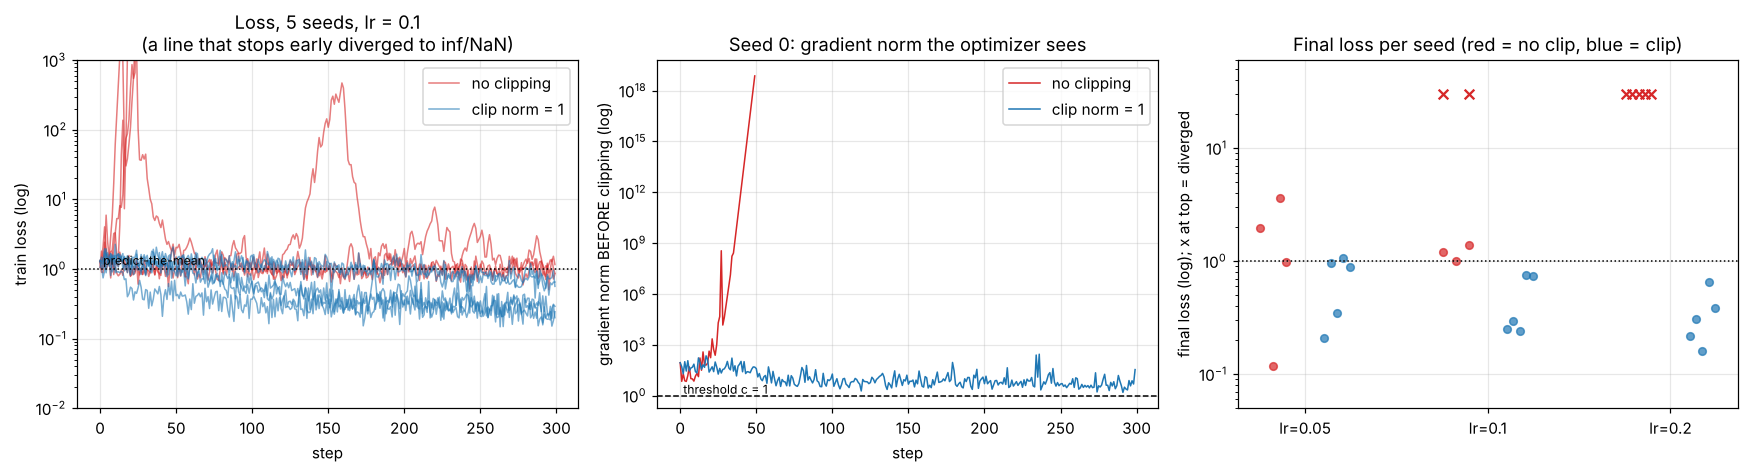

In [10]:
LR_SHOW = 0.1
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))

ax = axes[0]
for k, (clip, color) in enumerate(((None, "tab:red"), (1.0, "tab:blue"))):
    for i, r in enumerate(runs[(LR_SHOW, clip)]):
        ax.plot(r["loss"], color=color, alpha=0.6, lw=1, label=("no clipping" if clip is None else "clip norm = 1") if i == 0 else None)
ax.set_yscale("log"); ax.set_ylim(1e-2, 1e3)
ax.axhline(1.0, color="k", ls=":", lw=1); ax.text(2, 1.15, "predict-the-mean", fontsize=8)
ax.set_xlabel("step"); ax.set_ylabel("train loss (log)"); ax.set_title(f"Loss, 5 seeds, lr = {LR_SHOW}\n(a line that stops early diverged to inf/NaN)")
ax.legend()

ax = axes[1]
for clip, color in ((None, "tab:red"), (1.0, "tab:blue")):
    r = runs[(LR_SHOW, clip)][0]
    ax.semilogy(r["norm"], color=color, lw=1, label="no clipping" if clip is None else "clip norm = 1")
ax.axhline(1.0, color="k", ls="--", lw=1); ax.text(2, 1.3, "threshold c = 1", fontsize=8)
ax.set_xlabel("step"); ax.set_ylabel("gradient norm BEFORE clipping (log)")
ax.set_title("Seed 0: gradient norm the optimizer sees"); ax.legend()

ax = axes[2]
xs = np.arange(len(LRS)); width = 0.35
for k, (clip, color) in enumerate(((None, "tab:red"), (1.0, "tab:blue"))):
    for j, lr in enumerate(LRS):
        fl = summarize(runs[(lr, clip)])[3]
        xpos = xs[j] + (k - 0.5) * width
        spread = lambda n: xpos + (np.linspace(-0.07, 0.07, n) if n > 1 else np.zeros(n))
        ok = fl[~np.isnan(fl)]
        ax.scatter(spread(len(ok)), ok, color=color, alpha=0.7, s=25)
        nd = int(np.isnan(fl).sum())
        if nd:
            ax.scatter(spread(nd), [30] * nd, marker="x", color=color, s=40)
ax.set_yscale("log"); ax.set_ylim(5e-2, 60)
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set_xticks(xs); ax.set_xticklabels([f"lr={lr}" for lr in LRS])
ax.set_ylabel("final loss (log); x at top = diverged")
ax.set_title("Final loss per seed (red = no clip, blue = clip)")
plt.tight_layout(); plt.show()

**In our run** (exact numbers can shift slightly across PyTorch versions):

- Without clipping, seed 0's gradient norm climbs past 1e18 by about step 50 and the run diverges. With clipping the update stays bounded and the same run trains.
- At `lr = 0.1`, 2 of 5 unclipped runs diverged and 4 of 5 ended no better than predicting the mean; with clipping none diverged and the median final loss was 0.29. At `lr = 0.2` all 5 unclipped runs diverged and none of the clipped ones did.
- Clipping is **not** uniformly better. At the gentlest rate (`lr = 0.05`) unclipped runs did not all fail, and one reached the lowest loss of any run at that rate (about 0.12). Clipped runs were more consistent but slower, because a clipped step can be at most `lr x c` long.

## Experiment D: choosing the threshold

Clipping has a hyperparameter `c`. Too large and it never triggers; too small and every step is shrunk so much that learning crawls. Sweep `c` at `lr = 0.1` over 5 seeds, and also measure **what fraction of steps were actually clipped** (pre-clip norm above `c`).

In [11]:
THRESH = [0.01, 0.05, 0.2, 0.5, 1.0, 5.0, 50.0, None]
t0 = time.time()
sweep = {c: [train_rnn(clip=c, lr=0.1, seed=s) for s in SEEDS] for c in THRESH}
print(f"({time.time()-t0:.0f}s)")

print(f"{'clip c':>7s} | {'diverged':>8s} | {'median final loss':>17s} | {'median % of steps clipped':>26s}")
for c in THRESH:
    rs = sweep[c]
    nd, med, _, fl = summarize(rs)
    if c is None:
        pct = "-"
    else:
        pct = f"{np.median([100 * np.nanmean(r['norm'][~np.isnan(r['norm'])] > c) for r in rs]):.0f}%"
    print(f"{str(c):>7s} | {nd:>6d}/5 | {med:>17.3f} | {pct:>26s}")

(48s)
 clip c | diverged | median final loss |  median % of steps clipped
   0.01 |      0/5 |             1.242 |                       100%
   0.05 |      0/5 |             1.243 |                       100%
    0.2 |      0/5 |             1.131 |                       100%
    0.5 |      0/5 |             0.893 |                       100%
    1.0 |      0/5 |             0.292 |                       100%
    5.0 |      0/5 |             0.506 |                        70%
   50.0 |      0/5 |            77.825 |                        80%
   None |      2/5 |             1.208 |                          -


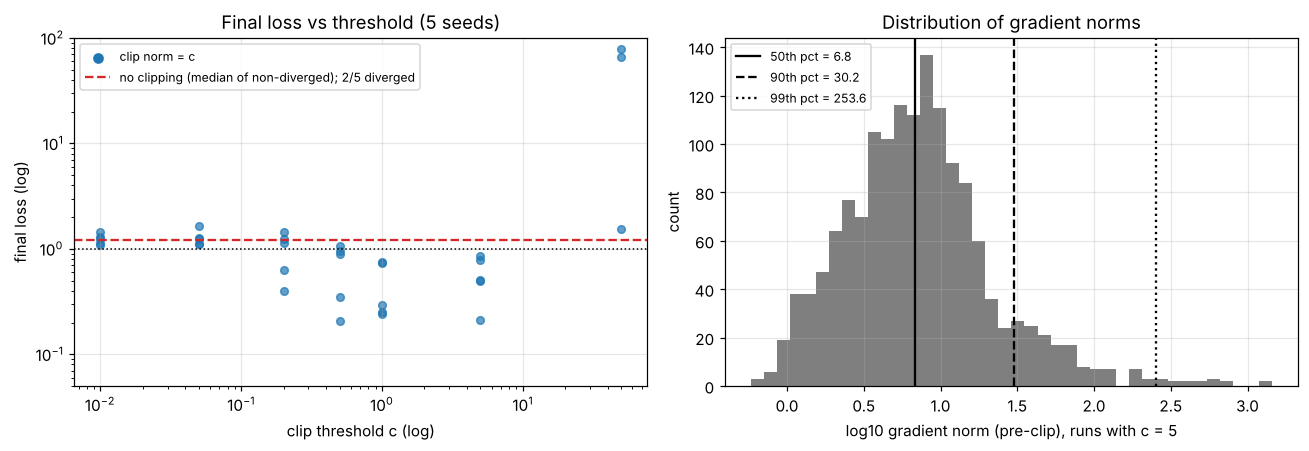

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
xs_num = [c for c in THRESH if c is not None]
for c in xs_num:
    fl = summarize(sweep[c])[3]
    ok = fl[~np.isnan(fl)]
    ax.scatter(np.full(len(ok), c), ok, color="tab:blue", alpha=0.7, s=25)
    if np.isnan(fl).any():
        ax.scatter([c] * int(np.isnan(fl).sum()), [60] * int(np.isnan(fl).sum()), marker="x", color="tab:blue")
ax.scatter([], [], color="tab:blue", label="clip norm = c")
nd, med, _, fl = summarize(sweep[None])
ok = fl[~np.isnan(fl)]
ax.axhline(med, color="tab:red", ls="--", label=f"no clipping (median of non-diverged); {nd}/5 diverged")
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(5e-2, 100)
ax.set_xlabel("clip threshold c (log)"); ax.set_ylabel("final loss (log)")
ax.set_title("Final loss vs threshold (5 seeds)"); ax.legend(fontsize=8)

ax = axes[1]
pooled = np.concatenate([r["norm"][~np.isnan(r["norm"])] for r in sweep[5.0]])
ax.hist(np.log10(pooled), bins=40, color="tab:gray")
for q, ls in ((50, "-"), (90, "--"), (99, ":")):
    v = np.percentile(pooled, q); ax.axvline(np.log10(v), color="k", ls=ls, label=f"{q}th pct = {v:.1f}")
ax.set_xlabel("log10 gradient norm (pre-clip), runs with c = 5")
ax.set_ylabel("count"); ax.set_title("Distribution of gradient norms"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**In our run:**

- `c <= 0.2`: every step is clipped and the final loss is about 1.1 to 1.2, no better than predicting the mean. The capped step is too short to make progress in 300 steps.
- `c = 0.5` to `5`: learns (median final loss 0.29 to 0.89). `c = 1` had the best median, but with 5 seeds and a wide spread per seed, do not read `1` vs `5` as a real difference.
- `c = 50`: clipping still fires on most steps, but a step of up to `lr x c = 5` is still destructive (median loss about 78).
- **The thresholds that worked were at or below the median pre-clip gradient norm** (about 6.8 in the `c = 5` runs; 90th percentile about 30, 99th about 254). In this unstable setting clipping was active on most steps, so the optimizer behaves like normalized gradient descent. The rule "set `c` at a high percentile so it rarely fires" would have picked something like `c = 30` to `250` here, which behaves like the failing `c = 50`.

So do not copy a threshold from another setup. Log the pre-clip norm in your own training run, look at its distribution, and sweep `c`. In a stable setup, where gradients are usually small, you would expect clipping to fire only occasionally and a larger `c` to be appropriate (we did not test that here).

## Experiment E: norm clipping vs value clipping

Both prevent a single huge step. They differ in what they do to the **direction** of the update. During training we record the cosine similarity between the raw gradient and the clipped gradient (1.0 = same direction). Both run at `lr = 0.1`, 5 seeds.

(17s)
      variant | diverged | median final loss |  mean cosine(raw, clipped) | 5th pct cosine
     norm c=1 |      0/5 |             0.292 |                      1.000 |          1.000
 value c=0.05 |      0/5 |             0.373 |                      0.778 |          0.688
  value c=0.5 |      0/5 |             0.741 |                      0.949 |          0.833


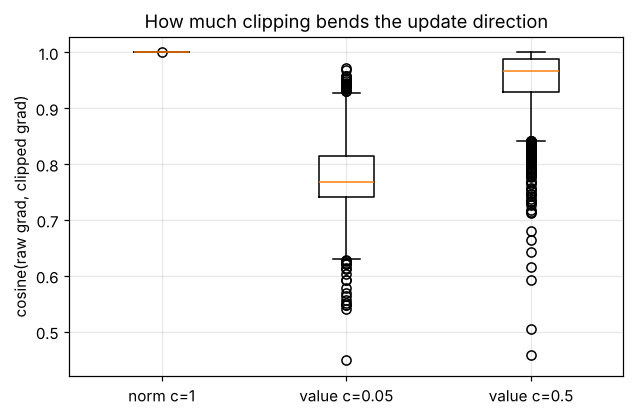

In [13]:
variants = {"norm c=1": dict(clip=1.0, mode="norm"),
            "value c=0.05": dict(clip=0.05, mode="value"),
            "value c=0.5": dict(clip=0.5, mode="value")}
t0 = time.time()
var_runs = {k: [train_rnn(lr=0.1, seed=s, track_cos=True, **cfg) for s in SEEDS] for k, cfg in variants.items()}
print(f"({time.time()-t0:.0f}s)")

print(f"{'variant':>13s} | {'diverged':>8s} | {'median final loss':>17s} | {'mean cosine(raw, clipped)':>26s} | {'5th pct cosine':>14s}")
for k, rs in var_runs.items():
    nd, med, _, _ = summarize(rs)
    cs = np.concatenate([r["cos"] for r in rs])
    print(f"{k:>13s} | {nd:>6d}/5 | {med:>17.3f} | {cs.mean():>26.3f} | {np.percentile(cs, 5):>14.3f}")

plt.figure(figsize=(6.5, 4))
plt.boxplot([np.concatenate([r["cos"] for r in rs]) for rs in var_runs.values()])
plt.xticks(range(1, len(var_runs) + 1), list(var_runs))
plt.ylabel("cosine(raw grad, clipped grad)"); plt.title("How much clipping bends the update direction")
plt.show()

## Experiment F: what clipping does *not* fix

Clipping only ever **shrinks** a gradient. It cannot enlarge a gradient that has already vanished. To see this, take an RNN with `rho = 0.5` (gradients vanish through time, as in Experiment B) and a task that needs **long memory**: predict the sum of the *first* 10 inputs of a length-50 sequence.

In [14]:
t0 = time.time()
vanish = {clip: [train_rnn(clip=clip, rho=0.5, lr=0.1, steps=300, seed=s, task="first10") for s in SEEDS]
          for clip in (None, 1.0)}
print(f"({time.time()-t0:.0f}s)")
for clip, rs in vanish.items():
    fl = np.array([final_loss(r) for r in rs])
    print(f"clip={str(clip):>4s}: final loss per seed {np.round(fl, 3)}   (1.0 = predict-the-mean)")
allnorms = np.concatenate([r["norm"][~np.isnan(r["norm"])] for r in vanish[1.0]])
print(f"pre-clip gradient norm (clip=1.0 runs): median {np.median(allnorms):.3f}, 99th pct {np.percentile(allnorms, 99):.3f}; "
      f"fraction of steps where clipping fired: {100 * np.mean(allnorms > 1.0):.1f}%")

(12s)
clip=None: final loss per seed [1.048 1.    1.097 0.991 1.046]   (1.0 = predict-the-mean)
clip= 1.0: final loss per seed [1.047 0.999 1.098 0.991 1.046]   (1.0 = predict-the-mean)
pre-clip gradient norm (clip=1.0 runs): median 0.716, 99th pct 1.692; fraction of steps where clipping fired: 19.7%


Fixing vanishing gradients needs a different tool: gated architectures (LSTM/GRU), skip connections (see the residual-connections notebook), better initialization, or normalization. Clipping and those tools are complementary: gated or residual nets still benefit from clipping when an occasional batch produces a spike.

## G. Practical recipe in PyTorch

```python
optimizer.zero_grad()
loss = model(batch).loss
loss.backward()

# 1. clip AFTER backward and BEFORE step
total_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

optimizer.step()

# 2. log total_norm every step: it is the pre-clip norm, and it tells you
#    how often clipping fires and whether a threshold is sensible
```

Things that are easy to get wrong:

- **Order matters.** Clip after `backward()` and before `step()`. Clipping before `backward()` does nothing.
- **Mixed precision (AMP).** Call `scaler.unscale_(optimizer)` *before* clipping so the threshold applies to true, unscaled gradients.
- **Gradient accumulation.** Clip once, after the last micro-batch has been accumulated, not after each micro-batch.
- **Clip globally, not per tensor,** unless you have a reason. `clip_grad_norm_` uses one global norm over all parameters, which preserves the update direction. Per-tensor clipping changes it.
- **Watch the returned norm.** If it is *frequently* above your threshold, clipping has become the effective learning-rate rule (as in Experiment D at small `c`), and you probably want a lower LR or a higher `c`. If it *never* exceeds the threshold, clipping is a harmless safety net.
- **Non-finite gradients.** `clip_grad_norm_(..., error_if_nonfinite=True)` raises instead of silently propagating NaN.
- **A common starting point** in many training recipes is `max_norm = 1.0`, but the right value depends on your loss scale and architecture; measure it.

## Summary

Numbers are from this notebook's executed run (5 seeds per setting, fixed seeds).

| Experiment | What we measured | Result |
|---|---|---|
| A | 49 starts x 4 learning rates on the single-neuron cliff | Clipping never did worse; it rescued 0 / 2 / 3 / 8 of 49 starts at lr 0.03 / 0.1 / 0.3 / 1.0. Modest on this toy. In the selected example, plain GD took one step of length about 4.2 onto a plateau (loss 0.09); clipped steps were capped at 0.3 and reached about 1e-4 |
| B | `||dL/dh_0|| / ||dL/dh_49||` in a tanh RNN at init | 9e-19 (rho 0.5), 2e-5 (1.0), 0.7 (1.5), 330 (2.0), 1e6 (3.0). Explosion appears clearly only for rho of 2 or more, because `tanh'` shrinks the product |
| C | RNN, rho 2.0, SGD, 3 learning rates | lr 0.1: unclipped 2/5 diverged and 4/5 no better than the mean; clipped 0/5 diverged, median loss 0.29. lr 0.2: unclipped 5/5 diverged; clipped 0/5, median 0.31. At lr 0.05 clipping was slower, and one unclipped seed did best |
| D | Threshold sweep at lr 0.1 | Too small (<= 0.2): no learning. 0.5 to 5: works. 50: fails. Working thresholds were at or below the median pre-clip norm, so clipping fired on 70 to 100% of steps |
| E | Norm vs value clipping | Norm: cosine to raw gradient is exactly 1.0, median loss 0.29. Value: c = 0.05 gave median loss 0.37 and mean cosine 0.78; c = 0.5 gave 0.74 and 0.95. No clear winner on loss here; the direction change is the real difference |
| F | Vanishing gradients (rho 0.5, long-memory task) | Final losses with and without clipping match to about 3 decimals (about 1.0, i.e. no learning), even though clipping fired on 19.7% of steps |

**Takeaways**

1. Clipping is a **stability** tool. It bounds the step length to at most `lr x c`, which stops the cycle "big gradient, big step, bigger loss, bigger gradient" that makes training diverge. In Experiment C that turned divergence at lr 0.1 and 0.2 into training.
2. It is **not free**. A threshold that is too small slows learning to a crawl (Experiment D), and at a gentle learning rate it can be slower than not clipping (Experiment C).
3. **Measure before choosing `c`.** Log the pre-clip norm. In our unstable setup the working thresholds sat below the median norm, not at a high percentile.
4. Prefer **norm clipping** when you want the update direction preserved; value clipping bends it (mean cosine 0.78 at c = 0.05).
5. It does **not** fix vanishing gradients. Use gated architectures, skip connections, or better initialization for that (Experiment F).

**Discussion questions**

1. In Experiment D, why is a threshold far below the typical gradient norm still able to train, and what is the optimizer effectively doing at that point?
2. Why does the notebook compare against "predict the mean" (loss 1.0) rather than just reporting loss?
3. Experiment A used a hand-selected example. What does the 49-start tally add, and why did the same start behave differently in float32 and float64 when we first tried it?
4. How would you decide `c` for a Transformer where gradient norms are usually stable and only occasional batches spike?